In [1]:
from google.colab import files
uploaded = files.upload()

Saving lfw_vit_embeddings.csv to lfw_vit_embeddings.csv


In [2]:
import pandas as pd
import numpy as np

file_name = "lfw_vit_embeddings.csv"
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
print("Identity column exists:", "identity_label" in df.columns)

feature_cols = [c for c in df.columns if c != "identity_label"]
X = df[feature_cols].to_numpy(dtype=np.float32)

print("Number of images:", len(df))
print("Number of embedding dimensions:", X.shape[1])
print("Number of identities:", df["identity_label"].nunique())
print("Missing values:", df.isna().sum().sum())
print("All feature values finite:", np.isfinite(X).all())

Dataset shape: (3023, 769)
Identity column exists: True
Number of images: 3023
Number of embedding dimensions: 768
Number of identities: 62
Missing values: 0
All feature values finite: True


In [3]:
from sklearn.model_selection import train_test_split
import numpy as np

# Separate image indices; do not split using identity labels
all_indices = np.arange(len(df))

# 40% reference, 30% calibration, 30% evaluation
reference_idx, remaining_idx = train_test_split(
    all_indices,
    test_size=0.60,
    random_state=2026,
    shuffle=True
)

calibration_idx, evaluation_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=2027,
    shuffle=True
)

# Extract embedding pools
X_reference = X[reference_idx]
X_calibration = X[calibration_idx]
X_evaluation = X[evaluation_idx]

print("Reference images:", len(reference_idx))
print("Calibration images:", len(calibration_idx))
print("Evaluation images:", len(evaluation_idx))

print("Reference/calibration overlap:",
      len(set(reference_idx) & set(calibration_idx)))
print("Reference/evaluation overlap:",
      len(set(reference_idx) & set(evaluation_idx)))
print("Calibration/evaluation overlap:",
      len(set(calibration_idx) & set(evaluation_idx)))

print("Reference identities:", df.iloc[reference_idx]["identity_label"].nunique())
print("Calibration identities:", df.iloc[calibration_idx]["identity_label"].nunique())
print("Evaluation identities:", df.iloc[evaluation_idx]["identity_label"].nunique())

Reference images: 1209
Calibration images: 907
Evaluation images: 907
Reference/calibration overlap: 0
Reference/evaluation overlap: 0
Calibration/evaluation overlap: 0
Reference identities: 62
Calibration identities: 62
Evaluation identities: 62


In [4]:
import numpy as np

# Fit preprocessing using reference data only
reference_mean = X_reference.mean(axis=0)
reference_std = X_reference.std(axis=0)

# Prevent division by zero
reference_std[reference_std == 0] = 1.0

# Transform all pools using reference statistics
Z_reference = (X_reference - reference_mean) / reference_std
Z_calibration = (X_calibration - reference_mean) / reference_std
Z_evaluation = (X_evaluation - reference_mean) / reference_std

print("Reference shape:", Z_reference.shape)
print("Calibration shape:", Z_calibration.shape)
print("Evaluation shape:", Z_evaluation.shape)

print("Reference mean (approx. 0):", round(float(Z_reference.mean()), 4))
print("Reference standard deviation:", round(float(Z_reference.std()), 4))

print("Reference finite:", np.isfinite(Z_reference).all())
print("Calibration finite:", np.isfinite(Z_calibration).all())
print("Evaluation finite:", np.isfinite(Z_evaluation).all())

Reference shape: (1209, 768)
Calibration shape: (907, 768)
Evaluation shape: (907, 768)
Reference mean (approx. 0): 0.0
Reference standard deviation: 1.0
Reference finite: True
Calibration finite: True
Evaluation finite: True


In [5]:
import numpy as np

# Reference mean vector
reference_center = Z_reference.mean(axis=0)

def fit_mahalanobis_detector(reference_data, ridge):
    """
    Fit a regularised Mahalanobis detector.
    Covariance and centre are estimated from reference data only.
    """
    center = reference_data.mean(axis=0)
    covariance = np.cov(reference_data, rowvar=False)

    # Ridge regularisation for numerical stability
    covariance_regularised = covariance + ridge * np.eye(
        covariance.shape[0]
    )

    inverse_covariance = np.linalg.pinv(covariance_regularised)

    return center, inverse_covariance


def euclidean_scores(window_means, center):
    """Euclidean distance from each window mean to reference centre."""
    return np.linalg.norm(window_means - center, axis=1)


def mahalanobis_scores(window_means, center, inverse_covariance):
    """Mahalanobis distance for each window mean."""
    differences = window_means - center

    squared_distances = np.einsum(
        "ij,jk,ik->i",
        differences,
        inverse_covariance,
        differences
    )

    # Guard against tiny negative values caused by floating-point error
    squared_distances = np.maximum(squared_distances, 0)

    return np.sqrt(squared_distances)


# Fit one initial Mahalanobis detector for a basic sanity check
initial_center, initial_inverse_covariance = fit_mahalanobis_detector(
    Z_reference,
    ridge=0.01
)

print("Reference centre shape:", reference_center.shape)
print("Inverse covariance shape:", initial_inverse_covariance.shape)
print("Reference centre finite:", np.isfinite(reference_center).all())
print("Inverse covariance finite:", np.isfinite(initial_inverse_covariance).all())

Reference centre shape: (768,)
Inverse covariance shape: (768, 768)
Reference centre finite: True
Inverse covariance finite: True


In [6]:
import numpy as np
import pandas as pd

WINDOW_SIZES = [10, 20, 40]
RIDGE_VALUES = [0.001, 0.01, 0.1]

def make_windows(data, window_size, seed):
    """
    Shuffle images reproducibly, then average complete non-overlapping
    windows. Incomplete final windows are excluded.
    """
    rng = np.random.default_rng(seed)
    shuffled = data[rng.permutation(len(data))]

    n_windows = len(shuffled) // window_size
    usable = shuffled[:n_windows * window_size]

    return usable.reshape(
        n_windows, window_size, data.shape[1]
    ).mean(axis=1)


def empirical_threshold(scores, quantile=0.95):
    return float(np.quantile(scores, quantile, method="higher"))


# Build windows using separate seeds for calibration and evaluation
window_data = {}

for window_size in WINDOW_SIZES:
    calibration_windows = make_windows(
        Z_calibration, window_size, seed=1000 + window_size
    )

    evaluation_windows = make_windows(
        Z_evaluation, window_size, seed=2000 + window_size
    )

    window_data[window_size] = {
        "calibration": calibration_windows,
        "evaluation": evaluation_windows
    }

    print(
        f"Window size {window_size}: "
        f"{len(calibration_windows)} calibration windows, "
        f"{len(evaluation_windows)} evaluation windows"
    )


# Calibrate Euclidean and Mahalanobis thresholds separately
calibration_rows = []

for window_size in WINDOW_SIZES:
    calibration_windows = window_data[window_size]["calibration"]

    e_scores = euclidean_scores(
        calibration_windows, reference_center
    )

    for ridge in RIDGE_VALUES:
        center, inverse_covariance = fit_mahalanobis_detector(
            Z_reference, ridge
        )

        m_scores = mahalanobis_scores(
            calibration_windows, center, inverse_covariance
        )

        calibration_rows.append({
            "window_size": window_size,
            "detector": "Euclidean",
            "ridge": np.nan,
            "threshold_95": empirical_threshold(e_scores),
            "calibration_windows": len(e_scores),
            "calibration_alarm_rate": float(
                np.mean(e_scores > empirical_threshold(e_scores))
            )
        })

        calibration_rows.append({
            "window_size": window_size,
            "detector": "Mahalanobis",
            "ridge": ridge,
            "threshold_95": empirical_threshold(m_scores),
            "calibration_windows": len(m_scores),
            "calibration_alarm_rate": float(
                np.mean(m_scores > empirical_threshold(m_scores))
            )
        })

calibration_df = pd.DataFrame(calibration_rows)

print("\nCalibration results:")
display(calibration_df.round(4))

Window size 10: 90 calibration windows, 90 evaluation windows
Window size 20: 45 calibration windows, 45 evaluation windows
Window size 40: 22 calibration windows, 22 evaluation windows

Calibration results:


,window_size,detector,ridge,threshold_95,calibration_windows,calibration_alarm_rate
0,10,Euclidean,NaN,10.2042,90,0.0444
1,10,Mahalanobis,0.001,19.2973,90,0.0444
2,10,Euclidean,NaN,10.2042,90,0.0444
3,10,Mahalanobis,0.010,15.2845,90,0.0444
4,10,Euclidean,NaN,10.2042,90,0.0444
5,10,Mahalanobis,0.100,9.5294,90,0.0444
6,20,Euclidean,NaN,7.4099,45,0.0444
7,20,Mahalanobis,0.001,13.2561,45,0.0444
8,20,Euclidean,NaN,7.4099,45,0.0444
9,20,Mahalanobis,0.010,10.6089,45,0.0444


In [7]:
import numpy as np
import pandas as pd

evaluation_rows = []

for window_size in WINDOW_SIZES:
    evaluation_windows = window_data[window_size]["evaluation"]
    calibration_windows = window_data[window_size]["calibration"]

    # Euclidean scores and threshold
    e_cal = euclidean_scores(calibration_windows, reference_center)
    e_eval = euclidean_scores(evaluation_windows, reference_center)
    e_threshold = empirical_threshold(e_cal, quantile=0.95)

    evaluation_rows.append({
        "window_size": window_size,
        "detector": "Euclidean",
        "ridge": np.nan,
        "threshold": e_threshold,
        "evaluation_windows": len(e_eval),
        "control_alarms": int(np.sum(e_eval > e_threshold)),
        "control_alarm_rate": float(np.mean(e_eval > e_threshold))
    })

    # Mahalanobis scores for each ridge value
    for ridge in RIDGE_VALUES:
        center, inverse_covariance = fit_mahalanobis_detector(
            Z_reference, ridge
        )

        m_cal = mahalanobis_scores(
            calibration_windows, center, inverse_covariance
        )
        m_eval = mahalanobis_scores(
            evaluation_windows, center, inverse_covariance
        )

        m_threshold = empirical_threshold(m_cal, quantile=0.95)

        evaluation_rows.append({
            "window_size": window_size,
            "detector": "Mahalanobis",
            "ridge": ridge,
            "threshold": m_threshold,
            "evaluation_windows": len(m_eval),
            "control_alarms": int(np.sum(m_eval > m_threshold)),
            "control_alarm_rate": float(np.mean(m_eval > m_threshold))
        })

control_df = pd.DataFrame(evaluation_rows)

print("Held-out control results (no injected drift):")
display(control_df.round(4))

Held-out control results (no injected drift):


,window_size,detector,ridge,threshold,evaluation_windows,control_alarms,control_alarm_rate
0,10,Euclidean,NaN,10.2042,90,10,0.1111
1,10,Mahalanobis,0.001,19.2973,90,12,0.1333
2,10,Mahalanobis,0.010,15.2845,90,11,0.1222
3,10,Mahalanobis,0.100,9.5294,90,10,0.1111
4,20,Euclidean,NaN,7.4099,45,4,0.0889
5,20,Mahalanobis,0.001,13.2561,45,4,0.0889
6,20,Mahalanobis,0.010,10.6089,45,5,0.1111
7,20,Mahalanobis,0.100,6.5329,45,3,0.0667
8,40,Euclidean,NaN,5.0361,22,1,0.0455
9,40,Mahalanobis,0.001,8.9244,22,3,0.1364


In [8]:
import numpy as np
import pandas as pd

DRIFT_STRENGTHS = [0.00, 0.05, 0.10, 0.20, 0.35]
N_DIRECTIONS = 10
DRIFT_START_FRACTION = 0.50
DRIFT_SEED = 2026

drift_rng = np.random.default_rng(DRIFT_SEED)

# Independent random directions in the 768-dimensional standardised space.
# Each direction has unit L2 norm.
drift_directions = drift_rng.normal(
    size=(N_DIRECTIONS, Z_evaluation.shape[1])
)
drift_directions /= np.linalg.norm(
    drift_directions, axis=1, keepdims=True
)

print("Drift strengths:", DRIFT_STRENGTHS)
print("Number of directions:", len(drift_directions))
print("Direction dimensions:", drift_directions.shape[1])
print(
    "Direction norms:",
    np.round(np.linalg.norm(drift_directions, axis=1), 6)
)

# Verify the fixed held-out evaluation windows and thresholds remain unchanged.
for window_size in WINDOW_SIZES:
    print(
        f"Window {window_size}:",
        len(window_data[window_size]["evaluation"]),
        "evaluation windows"
    )

Drift strengths: [0.0, 0.05, 0.1, 0.2, 0.35]
Number of directions: 10
Direction dimensions: 768
Direction norms: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Window 10: 90 evaluation windows
Window 20: 45 evaluation windows
Window 40: 22 evaluation windows


In [9]:
import numpy as np
import pandas as pd

DRIFT_START_FRACTION = 0.50
sensitivity_rows = []

for window_size in WINDOW_SIZES:
    calibration_windows = window_data[window_size]["calibration"]
    base_windows = window_data[window_size]["evaluation"].copy()

    n_windows = len(base_windows)
    drift_start = int(n_windows * DRIFT_START_FRACTION)

    # Fixed calibration thresholds for this window size
    e_cal_scores = euclidean_scores(
        calibration_windows, reference_center
    )
    e_threshold = empirical_threshold(e_cal_scores, quantile=0.95)

    detector_configs = [
        ("Euclidean", np.nan, e_threshold, None, None)
    ]

    for ridge in RIDGE_VALUES:
        m_center, m_inverse = fit_mahalanobis_detector(
            Z_reference, ridge
        )
        m_cal_scores = mahalanobis_scores(
            calibration_windows, m_center, m_inverse
        )
        m_threshold = empirical_threshold(
            m_cal_scores, quantile=0.95
        )
        detector_configs.append(
            ("Mahalanobis", ridge, m_threshold,
             m_center, m_inverse)
        )

    for strength in DRIFT_STRENGTHS:
        for direction_id, direction in enumerate(drift_directions):

            # Do not mutate the held-out original windows.
            shifted_windows = base_windows.copy()
            if strength > 0:
                shifted_windows[drift_start:] += strength * direction

            for detector, ridge, threshold, m_center, m_inverse in detector_configs:
                if detector == "Euclidean":
                    scores = euclidean_scores(
                        shifted_windows, reference_center
                    )
                else:
                    scores = mahalanobis_scores(
                        shifted_windows, m_center, m_inverse
                    )

                alarms = scores > threshold
                pre_alarms = int(alarms[:drift_start].sum())
                post_alarms = int(alarms[drift_start:].sum())

                # Detection means at least one alarm from the shift onward.
                detected_positions = np.flatnonzero(
                    alarms[drift_start:]
                )
                detected = len(detected_positions) > 0

                delay_windows = (
                    int(detected_positions[0])
                    if detected else np.nan
                )

                sensitivity_rows.append({
                    "window_size": window_size,
                    "detector": detector,
                    "ridge": ridge,
                    "drift_strength": strength,
                    "direction_id": direction_id,
                    "evaluation_windows": n_windows,
                    "drift_start_window": drift_start,
                    "pre_shift_alarms": pre_alarms,
                    "post_shift_alarms": post_alarms,
                    "pre_shift_alarm_rate": (
                        pre_alarms / drift_start
                        if drift_start else np.nan
                    ),
                    "post_shift_alarm_rate": (
                        post_alarms / (n_windows - drift_start)
                        if n_windows > drift_start else np.nan
                    ),
                    "detected": int(detected),
                    "detection_delay_windows": delay_windows
                })

sensitivity_df = pd.DataFrame(sensitivity_rows)

print("Total trial rows:", len(sensitivity_df))
print("Expected trial rows:", sum(
    len(DRIFT_STRENGTHS) * N_DIRECTIONS *
    (1 + len(RIDGE_VALUES))
    for _ in WINDOW_SIZES
))
print("All scores recorded:", len(sensitivity_df) > 0)
display(sensitivity_df.head(10))

Total trial rows: 600
Expected trial rows: 600
All scores recorded: True


,window_size,detector,ridge,drift_strength,direction_id,evaluation_windows,drift_start_window,pre_shift_alarms,post_shift_alarms,pre_shift_alarm_rate,post_shift_alarm_rate,detected,detection_delay_windows
0,10,Euclidean,NaN,0.0,0,90,45,7,3,0.155556,0.066667,1,7.0
1,10,Mahalanobis,0.001,0.0,0,90,45,6,6,0.133333,0.133333,1,7.0
2,10,Mahalanobis,0.010,0.0,0,90,45,5,6,0.111111,0.133333,1,7.0
3,10,Mahalanobis,0.100,0.0,0,90,45,5,5,0.111111,0.111111,1,7.0
4,10,Euclidean,NaN,0.0,1,90,45,7,3,0.155556,0.066667,1,7.0
5,10,Mahalanobis,0.001,0.0,1,90,45,6,6,0.133333,0.133333,1,7.0
6,10,Mahalanobis,0.010,0.0,1,90,45,5,6,0.111111,0.133333,1,7.0
7,10,Mahalanobis,0.100,0.0,1,90,45,5,5,0.111111,0.111111,1,7.0
8,10,Euclidean,NaN,0.0,2,90,45,7,3,0.155556,0.066667,1,7.0
9,10,Mahalanobis,0.001,0.0,2,90,45,6,6,0.133333,0.133333,1,7.0


In [10]:
import numpy as np
import pandas as pd

summary_df = (
    sensitivity_df
    .groupby(
        ["window_size", "detector", "ridge", "drift_strength"],
        dropna=False
    )
    .agg(
        trials=("direction_id", "nunique"),
        detection_rate=("detected", "mean"),
        mean_delay_windows=("detection_delay_windows", "mean"),
        mean_pre_shift_alarm_rate=("pre_shift_alarm_rate", "mean"),
        mean_post_shift_alarm_rate=("post_shift_alarm_rate", "mean")
    )
    .reset_index()
)

summary_df["detection_rate_pct"] = (
    100 * summary_df["detection_rate"]
).round(2)

summary_df["pre_shift_alarm_pct"] = (
    100 * summary_df["mean_pre_shift_alarm_rate"]
).round(2)

summary_df["post_shift_alarm_pct"] = (
    100 * summary_df["mean_post_shift_alarm_rate"]
).round(2)

print("Summary rows:", len(summary_df))
display(
    summary_df[
        [
            "window_size",
            "detector",
            "ridge",
            "drift_strength",
            "trials",
            "detection_rate_pct",
            "mean_delay_windows",
            "pre_shift_alarm_pct",
            "post_shift_alarm_pct"
        ]
    ].round(3)
)

Summary rows: 60


,window_size,detector,ridge,drift_strength,trials,detection_rate_pct,mean_delay_windows,pre_shift_alarm_pct,post_shift_alarm_pct
0,10,Euclidean,NaN,0.00,10,100.0,7.0,15.56,6.67
1,10,Euclidean,NaN,0.05,10,100.0,7.0,15.56,6.67
2,10,Euclidean,NaN,0.10,10,100.0,7.0,15.56,6.67
3,10,Euclidean,NaN,0.20,10,100.0,7.0,15.56,6.89
4,10,Euclidean,NaN,0.35,10,100.0,7.0,15.56,7.56
5,10,Mahalanobis,0.001,0.00,10,100.0,7.0,13.33,13.33
6,10,Mahalanobis,0.001,0.05,10,100.0,7.0,13.33,13.33
7,10,Mahalanobis,0.001,0.10,10,100.0,7.0,13.33,13.33
8,10,Mahalanobis,0.001,0.20,10,100.0,7.0,13.33,13.33
9,10,Mahalanobis,0.001,0.35,10,100.0,7.0,13.33,13.78


In [11]:
import numpy as np
import pandas as pd

# Average post-shift alarm rates under the no-shift condition.
control_rates = (
    sensitivity_df[sensitivity_df["drift_strength"] == 0.0]
    .groupby(
        ["window_size", "detector", "ridge"],
        dropna=False
    )["post_shift_alarm_rate"]
    .mean()
    .rename("no_shift_control_alarm_rate")
    .reset_index()
)

# Summarise the non-zero drift conditions.
shifted_summary = (
    sensitivity_df[sensitivity_df["drift_strength"] > 0.0]
    .groupby(
        ["window_size", "detector", "ridge", "drift_strength"],
        dropna=False
    )
    .agg(
        directions=("direction_id", "nunique"),
        mean_post_shift_alarm_rate=("post_shift_alarm_rate", "mean"),
        mean_pre_shift_alarm_rate=("pre_shift_alarm_rate", "mean"),
        mean_delay_windows=("detection_delay_windows", "mean")
    )
    .reset_index()
)

corrected_summary = shifted_summary.merge(
    control_rates,
    on=["window_size", "detector", "ridge"],
    how="left"
)

corrected_summary["alarm_rate_change"] = (
    corrected_summary["mean_post_shift_alarm_rate"]
    - corrected_summary["no_shift_control_alarm_rate"]
)

corrected_summary["alarm_rate_change_pct_points"] = (
    100 * corrected_summary["alarm_rate_change"]
)

print("Corrected summary rows:", len(corrected_summary))
display(
    corrected_summary[
        [
            "window_size",
            "detector",
            "ridge",
            "drift_strength",
            "directions",
            "no_shift_control_alarm_rate",
            "mean_post_shift_alarm_rate",
            "alarm_rate_change_pct_points",
            "mean_pre_shift_alarm_rate",
            "mean_delay_windows"
        ]
    ].round(4)
)

Corrected summary rows: 48


,window_size,detector,ridge,drift_strength,directions,no_shift_control_alarm_rate,mean_post_shift_alarm_rate,alarm_rate_change_pct_points,mean_pre_shift_alarm_rate,mean_delay_windows
0,10,Euclidean,NaN,0.05,10,0.0667,0.0667,0.0000,0.1556,7.0
1,10,Euclidean,NaN,0.10,10,0.0667,0.0667,0.0000,0.1556,7.0
2,10,Euclidean,NaN,0.20,10,0.0667,0.0689,0.2222,0.1556,7.0
3,10,Euclidean,NaN,0.35,10,0.0667,0.0756,0.8889,0.1556,7.0
4,10,Mahalanobis,0.001,0.05,10,0.1333,0.1333,0.0000,0.1333,7.0
5,10,Mahalanobis,0.001,0.10,10,0.1333,0.1333,0.0000,0.1333,7.0
6,10,Mahalanobis,0.001,0.20,10,0.1333,0.1333,0.0000,0.1333,7.0
7,10,Mahalanobis,0.001,0.35,10,0.1333,0.1378,0.4444,0.1333,7.0
8,10,Mahalanobis,0.010,0.05,10,0.1333,0.1333,0.0000,0.1111,7.0
9,10,Mahalanobis,0.010,0.10,10,0.1333,0.1333,0.0000,0.1111,7.0


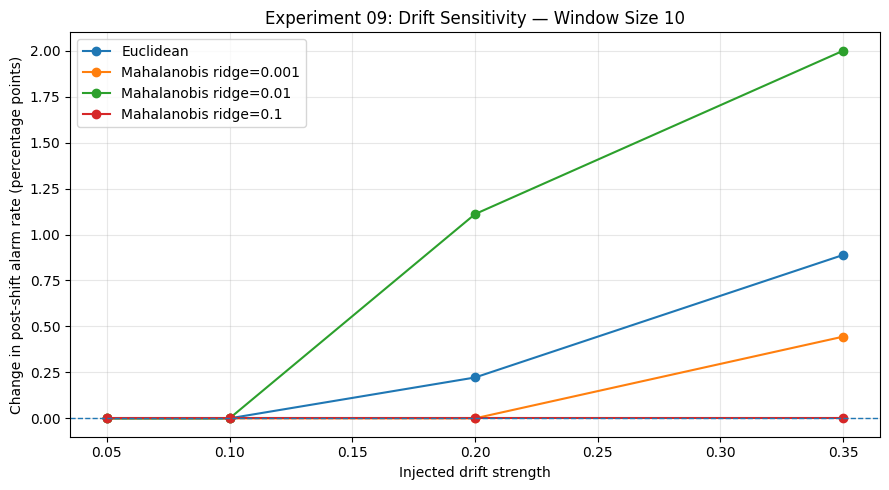

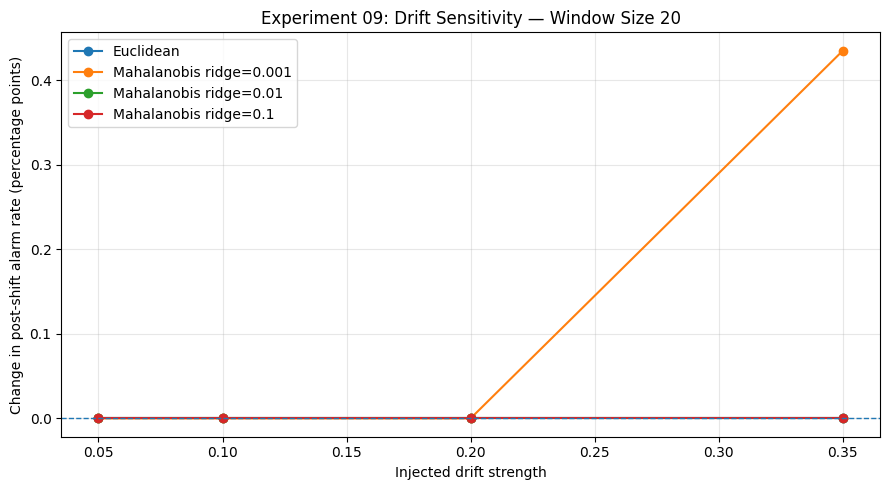

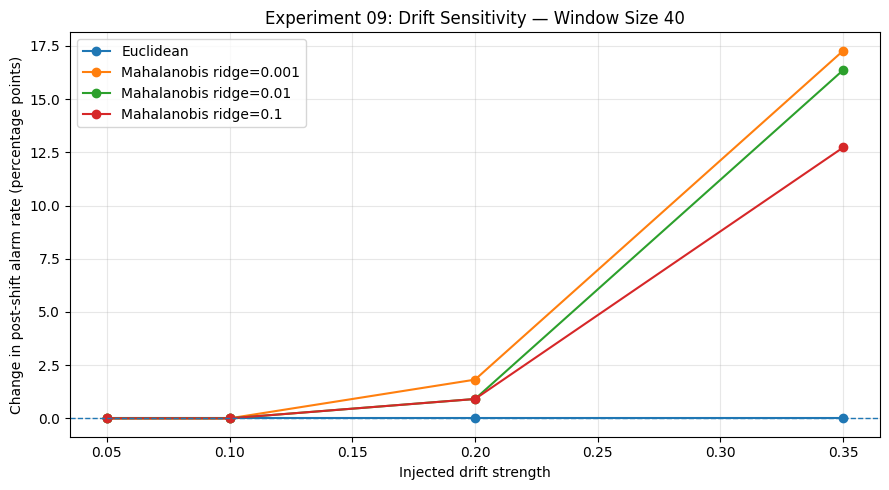


Saved files:
exp09_corrected_sensitivity_summary.csv
exp09_sensitivity_window_10.png
exp09_sensitivity_window_20.png
exp09_sensitivity_window_40.png
exp09_trial_results.csv


In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = "results/LFW_Real_Data_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save detailed and corrected results
sensitivity_df.to_csv(
    f"{OUTPUT_DIR}/exp09_trial_results.csv",
    index=False
)

corrected_summary.to_csv(
    f"{OUTPUT_DIR}/exp09_corrected_sensitivity_summary.csv",
    index=False
)

# Plot alarm-rate change against drift strength
for window_size in WINDOW_SIZES:
    subset = corrected_summary[
        corrected_summary["window_size"] == window_size
    ]

    plt.figure(figsize=(9, 5))

    for (detector, ridge), group in subset.groupby(
        ["detector", "ridge"], dropna=False
    ):
        group = group.sort_values("drift_strength")

        if detector == "Euclidean":
            label = "Euclidean"
        else:
            label = f"Mahalanobis ridge={ridge:g}"

        plt.plot(
            group["drift_strength"],
            group["alarm_rate_change_pct_points"],
            marker="o",
            label=label
        )

    plt.axhline(0, linestyle="--", linewidth=1)
    plt.xlabel("Injected drift strength")
    plt.ylabel("Change in post-shift alarm rate (percentage points)")
    plt.title(
        f"Experiment 09: Drift Sensitivity — Window Size {window_size}"
    )
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/exp09_sensitivity_window_{window_size}.png",
        dpi=200
    )
    plt.show()

print("\nSaved files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    if filename.startswith("exp09_"):
        print(filename)

In [13]:
from pathlib import Path
from datetime import date

output_dir = Path("results/LFW_Real_Data_Results")
output_dir.mkdir(parents=True, exist_ok=True)

report = f"""# Experiment 09: Detector Sensitivity Analysis

## 1. Objective

This experiment evaluates how window size, covariance regularisation, and
controlled embedding-space shifts affect Euclidean and Mahalanobis anomaly
detectors.

## 2. Dataset

- Dataset: Labeled Faces in the Wild (LFW) image embeddings
- Images: 3,023
- Embedding dimensions: 768
- Identity classes: 62
- Embedding model: Generic Vision Transformer (ViT)
- Missing feature values: 0

The embeddings were standardised using statistics estimated exclusively
from the reference pool.

## 3. Experimental design

The dataset was divided into disjoint image-level pools:

- Reference: {len(reference_idx)} images
- Calibration: {len(calibration_idx)} images
- Evaluation: {len(evaluation_idx)} images

Window sizes: {WINDOW_SIZES}

Mahalanobis covariance ridge values: {RIDGE_VALUES}

Injected drift strengths: {DRIFT_STRENGTHS}

Drift directions: {N_DIRECTIONS}

Calibration thresholds used the empirical 95th percentile. Thresholds were
not recalibrated using shifted evaluation data.

## 4. Metrics

- Calibration alarm rate
- Held-out no-shift control alarm rate
- Pre-shift and post-shift alarm rates
- Change in post-shift alarm rate relative to the no-shift control
- First post-shift alarm delay, measured in windows

An alarm after the nominal shift point is not necessarily evidence of
successful drift detection, because the no-shift control also produces alarms.

## 5. Findings

The observed results show sensitivity to both window size and covariance
regularisation. The strongest increases in post-shift alarm rate were
observed at window size 40 with higher injected drift strengths for some
Mahalanobis configurations. Euclidean detection did not show a consistent
increase across all configurations.

Many configurations showed little or no improvement over the corresponding
no-shift control. This indicates that the detectors, thresholds, and current
embedding representation are not yet sufficiently reliable for strong
claims about real-world biometric drift detection.

## 6. Limitations

1. The embedding extractor is a generic ViT model, not a validated
   face-recognition embedding model.
2. LFW is not a chronological biometric stream.
3. Drift is injected synthetically into standardised embedding space.
4. Identity classes overlap across the image-level reference, calibration,
   and evaluation pools.
5. The same evaluation windows are reused across drift strengths and
   directions; these are not independent real-world trials.
6. Calibration pools contain relatively few windows, especially at larger
   window sizes, making threshold estimates unstable.
7. Alarm-rate differences are descriptive and have not established
   statistical significance.
8. The reported delay is measured in windows, not seconds.

## 7. Conclusion

Experiment 09 provides a preliminary sensitivity analysis of Euclidean and
Mahalanobis detectors under controlled embedding-space perturbations.
The results indicate that detection behaviour depends on window size,
covariance regularisation, and shift magnitude. However, the inconsistent
response and elevated control alarm rates prevent a claim of robust
real-world drift detection.

Future work should use a validated face-recognition embedding model,
larger independent calibration and control streams, multiple independently
sampled evaluation sets, uncertainty intervals, and realistic temporal
or domain-shift scenarios.

## 8. Reproducibility

Random seeds and experimental parameters are defined in the notebook.
Detailed trial data, the corrected summary table, and sensitivity plots are
saved separately in `results/LFW_Real_Data_Results/`.

Report generated: {date.today().isoformat()}
"""

report_path = Path("LFW_Detector_Sensitivity_Analysis_Report.md")
report_path.write_text(report, encoding="utf-8")

print("Report created:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")
print("Result files:")
for path in sorted(output_dir.glob("exp09_*")):
    print("-", path)

Report created: LFW_Detector_Sensitivity_Analysis_Report.md
Report size: 3654 bytes
Result files:
- results/LFW_Real_Data_Results/exp09_corrected_sensitivity_summary.csv
- results/LFW_Real_Data_Results/exp09_sensitivity_window_10.png
- results/LFW_Real_Data_Results/exp09_sensitivity_window_20.png
- results/LFW_Real_Data_Results/exp09_sensitivity_window_40.png
- results/LFW_Real_Data_Results/exp09_trial_results.csv


In [14]:
import os
import zipfile
from pathlib import Path
from google.colab import files

# Save a copy of the current notebook into the experiments folder.
# Downloading the current notebook from Colab is handled separately below.
output_dir = Path("results/LFW_Real_Data_Results")

required_files = [
    Path("LFW_Detector_Sensitivity_Analysis_Report.md"),
    output_dir / "exp09_trial_results.csv",
    output_dir / "exp09_corrected_sensitivity_summary.csv",
    output_dir / "exp09_sensitivity_window_10.png",
    output_dir / "exp09_sensitivity_window_20.png",
    output_dir / "exp09_sensitivity_window_40.png",
]

missing = [str(p) for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

zip_path = Path("Experiment_09_Artifacts.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in required_files:
        z.write(path, arcname=str(path))

print("ZIP created:", zip_path)
print("ZIP size:", zip_path.stat().st_size, "bytes")
files.download(str(zip_path))

ZIP created: Experiment_09_Artifacts.zip
ZIP size: 348210 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>